# Pertemuan 7: Kebocoran Data, Diagnosis Model, Seleksi Fitur, dan Analisis Kesalahan

Pertemuan 5 memilih *stacking* Multinomial Naive Bayes + Logistic Regression + LightGBM sebagai kandidat model akhir. Pertemuan 6 menemukan bahwa format angka berbeda antar sumber data, sehingga model mungkin mengenali Phish dari formatnya, bukan dari isinya (Hipotesis 4). Notebook ini memeriksa dan memperbaiki kandidat tersebut dalam enam langkah:

1. **Uji Hipotesis 4**: menyeragamkan format angka dan tanggal, lalu mengukur penurunan performa.
2. **Pemeriksaan *near-duplicate***: pesan validasi yang hampir sama dengan pesan training.
3. **Diagnosis bias–variance dan tuning lanjutan**: `alpha`, jumlah pohon LightGBM, dan *learning curve*.
4. **Seleksi fitur** dengan chi-square dan pentingnya fitur pada LightGBM.
5. **Model akhir** pada teks yang diseragamkan, termasuk uji *stacking* tanpa Multinomial Naive Bayes.
6. **Analisis kesalahan** pada pesan individual.

Seluruh eksperimen hanya memakai data training dengan lima fold yang sama seperti Pertemuan 5. Data testing tetap disimpan untuk evaluasi akhir.

# A. Data dan Persiapan

Sel berikut memuat library dan dataset, menjalankan preprocessing yang sama dengan Pertemuan 3 sampai 6, lalu menyisihkan data testing.

Hasil penting notebook ini (prediksi *out-of-fold*, konfigurasi model, dan log eksperimen) disimpan ke folder artefak. Di Google Colab, folder ini berada di Google Drive agar tidak hilang saat sesi berakhir. Colab akan meminta izin akses Drive saat sel ini dijalankan.

In [ ]:
import sys
import subprocess
import os
import time
import gc
import json
import warnings

def ensure(package, module=None):
    try:
        __import__(module or package)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

ensure('datasets')
ensure('lightgbm')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import sklearn
import lightgbm as lgb
from datasets import load_dataset
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold

warnings.filterwarnings('ignore', message='X does not have valid feature names')
pd.set_option('display.max_colwidth', 200)

RANDOM_STATE = 42
DATASET_NAME = 'locuoco/the-biggest-spam-ham-phish-email-dataset-300000'
LABEL_NAMES = {0: 'Ham', 1: 'Phish', 2: 'Spam'}
CLASS_IDS = [0, 1, 2]
CLASS_ORDER = [LABEL_NAMES[c] for c in CLASS_IDS]

ARTIFACT_DIR = 'm07_artifacts'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ARTIFACT_DIR = '/content/drive/MyDrive/Group1_ML/m07_artifacts'
except Exception:
    pass
os.makedirs(ARTIFACT_DIR, exist_ok=True)
CACHE_DIR = 'm07_cache'
os.makedirs(CACHE_DIR, exist_ok=True)

raw_df = load_dataset(DATASET_NAME, split='train').to_pandas()
data = raw_df[['text', 'label']].dropna(subset=['text', 'label']).copy()
data = data[data['label'].isin(CLASS_IDS)].copy()
data['label'] = data['label'].astype(int)
data['clean_text'] = data['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
data = data[data['clean_text'].ne('')].copy()
data['dedup_key'] = data['clean_text'].str.lower()
labels_per_key = data.groupby('dedup_key')['label'].nunique()
data = data.loc[~data['dedup_key'].isin(labels_per_key[labels_per_key.gt(1)].index)]
df_clean = (
    data.drop_duplicates(subset=['dedup_key'], keep='first')
    [['clean_text', 'label']]
    .rename(columns={'clean_text': 'text'})
    .reset_index(drop=True)
)
del raw_df, data
gc.collect()

# Bagian testing (20%) tidak disimpan: data testing tidak dipakai pada notebook ini.
X_train, _, y_train, _ = train_test_split(
    df_clean['text'], df_clean['label'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df_clean['label']
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.to_numpy()
del df_clean
gc.collect()

folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))
print(f'Jumlah data training: {len(X_train):,} (Pertemuan 3: 223,152)')
print(f'Folder artefak     : {ARTIFACT_DIR}')
print(f'Versi library      : scikit-learn {sklearn.__version__}, lightgbm {lgb.__version__}, '
      f'pandas {pd.__version__}, numpy {np.__version__}')

README.md:   0%|          | 0.00/990 [00:00<?, ?B/s]

df.csv: reconstructing file:   0%|          |  0.00B /  631MB            

df.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/365448 [00:00<?, ? examples/s]

Jumlah data training: 223,152 (Pertemuan 3: 223,152)
Folder artefak     : m07_artifacts
Versi library      : scikit-learn 1.6.1, lightgbm 4.6.0, pandas 2.2.3, numpy 2.4.6


Sel berikut menyiapkan fungsi yang sama dengan Pertemuan 5: perhitungan metrik, validasi silang dengan prediksi *out-of-fold*, dan pergeseran threshold Ham. Target bisnis tetap sama: Ham Recall minimal 99,5%.

In [ ]:
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score

HAM_RECALL_TARGET = 0.995
TIE_TOLERANCE = 0.001
METRICS = ['Macro F1', 'Ham Recall', 'Phish Recall', 'Phish Precision', 'PR-AUC Phish']
ERROR_PAIRS = [(0, 2), (0, 1), (1, 0), (1, 2), (2, 1), (2, 0)]
ERROR_LABELS = [f'{LABEL_NAMES[a]} → {LABEL_NAMES[p]}' for a, p in ERROR_PAIRS]
cv_results = {}


def compute_metrics(y_true, y_pred, phish_score):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    return {
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'Ham Recall': cm[0, 0] / cm[0].sum(),
        'Phish Recall': cm[1, 1] / cm[1].sum(),
        'Phish Precision': cm[1, 1] / max(cm[:, 1].sum(), 1),
        'PR-AUC Phish': average_precision_score(y_true == 1, phish_score),
    }


def predict_with_ham_bias(log_proba, ham_bias=0.0):
    adjusted = log_proba.copy()
    adjusted[:, 0] += ham_bias
    return adjusted.argmax(axis=1)


def error_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    return {label: int(cm[a, p]) for label, (a, p) in zip(ERROR_LABELS, ERROR_PAIRS)}


def change_text(delta):
    if abs(delta) < TIE_TOLERANCE:
        return 'hampir tidak berubah'
    return f'naik {delta:.4f}' if delta > 0 else f'turun {abs(delta):.4f}'


def load_fold(k, representation):
    tr, va = folds[k]
    X_tr = sp.load_npz(f'{CACHE_DIR}/{representation}_tr_{k}.npz')
    X_va = sp.load_npz(f'{CACHE_DIR}/{representation}_va_{k}.npz')
    return X_tr, y_train[tr], X_va


def store_result(name, log_proba, configuration, minutes):
    cv_results[name] = {
        'log_proba': log_proba,
        'folds': pd.DataFrame([
            compute_metrics(y_train[va], log_proba[va].argmax(axis=1), log_proba[va, 1]) for _, va in folds
        ]),
        'konfigurasi': configuration,
        'menit': minutes,
    }


def run_cv(name, representation, fit_predict, configuration):
    # fit_predict(X_tr, y_tr, X_va, k) mengembalikan log-probabilitas data validasi (n × 3).
    log_proba = np.zeros((len(y_train), 3))
    start = time.perf_counter()
    for k, (tr, va) in enumerate(folds):
        X_tr, y_tr, X_va = load_fold(k, representation)
        log_proba[va] = fit_predict(X_tr, y_tr, X_va, k)
        del X_tr, X_va
        gc.collect()
    store_result(name, log_proba, configuration, (time.perf_counter() - start) / 60)


def mean_metric(name, metric, ham_bias=0.0):
    return per_fold_metrics(name, ham_bias)[metric].mean()


def per_fold_metrics(name, ham_bias=0.0):
    if ham_bias == 0.0:
        return cv_results[name]['folds']
    log_proba = cv_results[name]['log_proba']
    return pd.DataFrame([
        compute_metrics(y_train[va], predict_with_ham_bias(log_proba[va], ham_bias), log_proba[va, 1])
        for _, va in folds
    ])


def summary_table(names):
    rows = []
    for name in names:
        scores = per_fold_metrics(name)
        row = {'model': name, 'konfigurasi': cv_results[name]['konfigurasi']}
        for metric in METRICS:
            row[metric] = f'{scores[metric].mean():.4f} ± {scores[metric].std(ddof=0):.4f}'
        row['waktu (menit)'] = round(cv_results[name]['menit'], 1)
        rows.append(row)
    return pd.DataFrame(rows)


def mnb_fit_predict(alpha, selector_k=None):
    from sklearn.naive_bayes import MultinomialNB
    from sklearn.feature_selection import SelectKBest, chi2

    def fit_predict(X_tr, y_tr, X_va, k):
        if selector_k is not None and selector_k < X_tr.shape[1]:
            selector = SelectKBest(chi2, k=selector_k).fit(X_tr, y_tr)
            X_tr, X_va = selector.transform(X_tr), selector.transform(X_va)
        return MultinomialNB(alpha=alpha).fit(X_tr, y_tr).predict_log_proba(X_va)
    return fit_predict


def lr_fit_predict(C):
    from sklearn.linear_model import LogisticRegression

    def fit_predict(X_tr, y_tr, X_va, k):
        model = LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE).fit(X_tr, y_tr)
        return model.predict_log_proba(X_va)
    return fit_predict

# B. Uji Hipotesis 4: Format Angka dan Tanggal

## B.1 Tiga Versi Teks

### Bagaimana ciri ini ditemukan

Ciri sumber data ditemukan dan diuji melalui lima langkah berurutan:

| Langkah | Bukti | Bagian |
| ---: | --- | --- |
| 1 | Clustering tanpa label menghasilkan satu cluster berisi 99,8% Phish (17.281 pesan, sekitar separuh Phish training). Kata khas cluster tersebut adalah `2008 aug 06 wed 07 thu 0000 0300`, yaitu tanggal dan jam, bukan isi pesan. | Pertemuan 6, D.2 |
| 2 | Token `escape…` muncul pada 75,1% Ham dan 67,0% Spam, tetapi hanya 0,3% Phish. Sebaliknya, angka asli muncul pada 93,4% Phish, tetapi hanya 12,2% Ham dan 10,2% Spam. Sumber Phish tidak mengganti angka dengan token pengganti. | Pertemuan 6, E |
| 3 | Tanggal dan jam tersebut berasal dari *timestamp header* email, misalnya `tue 05 aug 2008 193121 0400`. *Header* serupa juga ada pada Ham dan Spam, tetapi angkanya sudah diganti `escapenumber` oleh sumber datanya. Tabel pada sel berikut menghitung berapa persen pesan setiap kelas yang memuat *timestamp*. | B.1 |
| 4 | Jika ciri tersebut menyebabkan bias, menghapusnya akan menurunkan performa. | B.3 |
| 5 | Jika ciri tersebut menyebabkan bias, kata yang paling menunjukkan Phish pada teks asli akan berupa angka atau tanggal, dan kata tersebut akan hilang setelah penyeragaman. | B.4 |

### Tiga versi teks

Email nyata tidak memiliki perbedaan format seperti ini. Jika model memakai format tersebut sebagai petunjuk, performanya pada email baru akan lebih rendah daripada hasil validasi. Untuk mengukurnya, setiap model dilatih pada tiga versi teks:

| Versi | Perubahan |
| --- | --- |
| V0 | Teks apa adanya. |
| V1 | Tanda baca diganti spasi. Setiap kata yang mengandung angka dan setiap token `escape…` diganti dengan satu token `numtoken`. |
| V2 | Tanda baca diganti spasi. *Timestamp header* email dihapus seluruhnya, baik yang angkanya asli (`tue 05 aug 2008 193121 0400`) maupun yang angkanya sudah diganti token `escape…` oleh sumber data (`friday june escapenumber escapenumber`). Setelah itu, angka diganti `numtoken` seperti V1, dan nama bulan atau hari yang tersisa diganti `datetoken`. |

Alasan setiap langkah V2:

- **Tanda baca diganti spasi** karena sumber Ham dan Spam menyimpan tanda baca sebagai token terpisah (`sent : monday , october 01`), sedangkan sumber Phish tidak. Vectorizer sudah mengabaikan tanda baca, sehingga langkah ini tidak mengubah kata yang dipakai model; langkah ini hanya membuat pola *timestamp* dapat dikenali dengan cara yang sama pada semua kelas.
- ***Timestamp header* dihapus seluruhnya** karena *timestamp* adalah bagian *header*, bukan isi pesan. Penghapusan berlaku untuk semua kelas, termasuk *timestamp* yang angkanya sudah menjadi `escapenumber`. Jika hanya *timestamp* dengan angka asli yang dihapus, *timestamp* Ham dan Spam akan tersisa dan nama hari atau bulan berbalik menjadi petunjuk sumber Ham.
- **Nama bulan dan hari yang tersisa diganti `datetoken`** agar penulisan tanggal di dalam isi pesan seragam. Kata `may` tidak diganti karena sangat sering dipakai sebagai kata kerja bahasa Inggris.

**Aturan keputusan, ditetapkan sebelum melihat hasil.** Model akhir memakai **V2**, karena format sumber data tidak tersedia pada email nyata. Selisih performa antara V0 dan V2 dilaporkan sebagai besarnya ketergantungan model pada format sumber data. Hipotesis 4 dianggap didukung jika Macro F1 turun lebih dari 0,005 pada salah satu model, yaitu sekitar lima kali simpangan baku antar fold pada Pertemuan 5.

Pola yang dipakai untuk setiap langkah tertulis pada sel berikut (`PUNCTUATION_PATTERN`, `TIMESTAMP_PATTERN`, `NUMBER_PATTERN`, `DATE_PATTERN`) dan juga disimpan pada `final_config.json`. Sel berikut membentuk ketiga versi teks, menampilkan contoh potongan pesan sebelum dan sesudah penyeragaman, lalu mengukur seberapa banyak ciri tanggal yang tersisa pada setiap kelas.

In [ ]:
import re

PUNCTUATION_PATTERN = r'[^\w\s]'
NUMBER_PATTERN = r'\b\w*(?:escapenumber|escapelong)\w*\b|\b\w*\d\w*\b'
DAYS = 'monday tuesday wednesday thursday friday saturday sunday mon tue tues wed thu thur thurs fri sat sun'.split()
MONTHS = ('january february march april may june july august september october november december '
          'jan feb mar apr jun jul aug sep sept oct nov dec').split()
DAY_ALT, MONTH_ALT = '|'.join(DAYS), '|'.join(MONTHS)
# Setiap posisi angka pada timestamp boleh berupa angka asli atau token escape… dari sumber data.
ESCAPE = r'escape\w*'
DAY_NUM, SHORT_NUM = r'(?:\d{1,2}|' + ESCAPE + ')', r'(?:\d{1,2}|' + ESCAPE + ')'
YEAR_NUM, CLOCK_NUM = r'(?:\d{4}|' + ESCAPE + ')', r'(?:\d{3,6}|' + ESCAPE + ')'
TIME_PART = (r'(?:\s+' + SHORT_NUM + r'\s+' + SHORT_NUM + r'(?:\s+' + SHORT_NUM + r')?|\s+' + CLOCK_NUM + r')?'
             r'(?:\s+(?:am|pm))?(?:\s+' + YEAR_NUM + r'|\s+[a-z]{3})?')
TIMESTAMP_PATTERN = (r'\b(?:(?:' + DAY_ALT + r')\s+)?(?:' + DAY_NUM + r'\s+(?:' + MONTH_ALT + r')|(?:' + MONTH_ALT
                     + r')\s+' + DAY_NUM + r')\s+' + YEAR_NUM + TIME_PART + r'\b')
DATE_PATTERN = r'\b(?:' + '|'.join(w for w in DAYS + MONTHS if w != 'may') + r')\b'


def to_plain(texts):
    return texts.str.lower().str.replace(PUNCTUATION_PATTERN, ' ', regex=True)


def normalize_v1(texts):
    return to_plain(texts).str.replace(NUMBER_PATTERN, ' numtoken ', regex=True)


def normalize_v2(texts):
    return (to_plain(texts)
            .str.replace(TIMESTAMP_PATTERN, ' ', regex=True)
            .str.replace(NUMBER_PATTERN, ' numtoken ', regex=True)
            .str.replace(DATE_PATTERN, ' datetoken ', regex=True))


start_time = time.perf_counter()
plain_text = to_plain(X_train)
TEXT_VARIANTS = {'V0': X_train, 'V1': normalize_v1(X_train), 'V2': normalize_v2(X_train)}
print(f'Penyeragaman teks selesai dalam {time.perf_counter() - start_time:.0f} detik')


def show_window(index, pattern, title):
    text = plain_text.iloc[index]
    match = re.search(pattern, text)
    if match is None:
        return
    window = pd.Series([text[max(0, match.start() - 40): match.end() + 40]])
    versions = [window.iloc[0], normalize_v1(window).iloc[0], normalize_v2(window).iloc[0]]
    rows = '\n'.join(f'| {name} | `{" ".join(value.split())}` |' for name, value in zip(['V0', 'V1', 'V2'], versions))
    display(Markdown(f'**{title}**\n\n| Versi | Potongan teks |\n| --- | --- |\n{rows}'))


has_timestamp = plain_text.str.contains(TIMESTAMP_PATTERN, regex=True).to_numpy()
phish_ts = np.flatnonzero((y_train == 1) & has_timestamp)
ham_escape = np.flatnonzero((y_train == 0) & X_train.str.contains(r'\bescapenumber\b', regex=True).to_numpy())
if len(phish_ts):
    show_window(phish_ts[0], TIMESTAMP_PATTERN, 'Contoh Phish dengan timestamp header')
if len(ham_escape):
    show_window(ham_escape[0], r'\bescapenumber\b', 'Contoh Ham dengan token escapenumber')

year_pattern = r'\b(?:19|20)\d{2}\b'
source_rows = []
for c in CLASS_IDS:
    mask = y_train == c
    v2_text = plain_text[mask].str.replace(TIMESTAMP_PATTERN, ' ', regex=True)
    source_rows.append({
        'kelas': LABEL_NAMES[c],
        'timestamp header (%)': has_timestamp[mask].mean() * 100,
        'tahun (V0, %)': plain_text[mask].str.contains(year_pattern, regex=True).mean() * 100,
        'tahun setelah timestamp dihapus (%)': v2_text.str.contains(year_pattern, regex=True).mean() * 100,
        'nama bulan/hari (V0, %)': plain_text[mask].str.contains(DATE_PATTERN, regex=True).mean() * 100,
        'nama bulan/hari setelah timestamp dihapus (%)': v2_text.str.contains(DATE_PATTERN, regex=True).mean() * 100,
    })
display(Markdown('**Ciri tanggal per kelas sebelum dan sesudah timestamp header dihapus**'))
display(pd.DataFrame(source_rows).round(1))
del plain_text
gc.collect()

Penyeragaman teks selesai dalam 197 detik


**Contoh Phish dengan timestamp header**

| Versi | Potongan teks |
| --- | --- |
| V0 | `ove going leave httpubornforgivenesscom thu 07 aug 2008 081037 0300` |
| V1 | `ove going leave httpubornforgivenesscom thu numtoken aug numtoken numtoken numtoken` |
| V2 | `ove going leave httpubornforgivenesscom` |

**Contoh Ham dengan token escapenumber**

| Versi | Potongan teks |
| --- | --- |
| V0 | `ge brawner sandra f sent monday october escapenumber escapenumber escapenumber escapenumber` |
| V1 | `ge brawner sandra f sent monday october numtoken numtoken numtoken numtoken` |
| V2 | `ge brawner sandra f sent` |

**Ciri tanggal per kelas sebelum dan sesudah timestamp header dihapus**

,kelas,timestamp header (%),"tahun (V0, %)",tahun setelah timestamp dihapus (%),"nama bulan/hari (V0, %)",nama bulan/hari setelah timestamp dihapus (%)
0,Ham,41.1,7.3,5.7,57.6,33.8
1,Phish,67.6,73.5,22.9,71.5,10.6
2,Spam,10.8,3.1,2.4,18.7,12.0


53

## B.2 Persiapan Fold

Sel berikut melatih vectorizer pada data latih setiap fold untuk ketiga versi teks, lalu menyimpan matriksnya ke disk.

| Representasi | Versi teks | Dipakai untuk |
| --- | --- | --- |
| TF-IDF unigram, seluruh kosakata | V0, V1, V2 | Logistic Regression (uji Hipotesis 4 dan model akhir) |
| Count unigram, `min_df=2` | V0, V1, V2 | Multinomial Naive Bayes (uji Hipotesis 4) |
| Count unigram + bigram, `min_df=2` | V2 | Multinomial Naive Bayes dan LightGBM pada model akhir |

Uji Hipotesis 4 untuk Multinomial Naive Bayes memakai unigram saja. Bigram untuk tiga versi teks akan melipatgandakan waktu persiapan, sedangkan pertanyaannya hanya seberapa besar pengaruh format angka. Count unigram V2 diambil dari kolom unigram matriks unigram + bigram V2, sehingga ketiga versi memakai aturan `min_df=2` yang sama.

Langkah ini membutuhkan sekitar 50 menit.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


def save_pair(name, k, X_tr, X_va):
    sp.save_npz(f'{CACHE_DIR}/{name}_tr_{k}.npz', X_tr.tocsr(), compressed=False)
    sp.save_npz(f'{CACHE_DIR}/{name}_va_{k}.npz', X_va.tocsr(), compressed=False)


fold_rows = []
for k, (tr, va) in enumerate(folds):
    start = time.perf_counter()
    for variant in ['V0', 'V1', 'V2']:
        texts = TEXT_VARIANTS[variant]
        tfidf_vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 1), sublinear_tf=True, dtype=np.float32)
        save_pair(f'tfidf_{variant}', k, tfidf_vec.fit_transform(texts.iloc[tr]), tfidf_vec.transform(texts.iloc[va]))
        del tfidf_vec
        if variant != 'V2':
            count_vec = CountVectorizer(lowercase=True, ngram_range=(1, 1), min_df=2, dtype=np.float32)
            save_pair(f'count1_{variant}', k, count_vec.fit_transform(texts.iloc[tr]), count_vec.transform(texts.iloc[va]))
            if k == 0:
                np.save(f'{CACHE_DIR}/terms1_{variant}_0.npy', count_vec.get_feature_names_out(), allow_pickle=True)
            del count_vec
        gc.collect()

    count_vec = CountVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, dtype=np.float32)
    count_tr = count_vec.fit_transform(TEXT_VARIANTS['V2'].iloc[tr])
    count_va = count_vec.transform(TEXT_VARIANTS['V2'].iloc[va])
    unigram_mask = np.zeros(count_tr.shape[1], dtype=bool)
    for term, index in count_vec.vocabulary_.items():
        unigram_mask[index] = ' ' not in term
    terms = np.empty(count_tr.shape[1], dtype=object)
    for term, index in count_vec.vocabulary_.items():
        terms[index] = term
    np.save(f'{CACHE_DIR}/unigram_mask_{k}.npy', unigram_mask)
    np.save(f'{CACHE_DIR}/terms_{k}.npy', terms, allow_pickle=True)
    save_pair('count12_V2', k, count_tr, count_va)
    save_pair('count1_V2', k, count_tr[:, unigram_mask], count_va[:, unigram_mask])
    fold_rows.append({'fold': k + 1, 'fitur count unigram + bigram V2': count_tr.shape[1],
                      'waktu (menit)': round((time.perf_counter() - start) / 60, 1)})
    del count_vec, count_tr, count_va, terms
    gc.collect()
display(pd.DataFrame(fold_rows))

,fold,fitur count unigram + bigram V2,waktu (menit)
0,1,3192234,10.5
1,2,2982808,11.0
2,3,3160733,12.5
3,4,3154363,11.5
4,5,3161347,11.5


## B.3 Hasil

Sel berikut melatih Multinomial Naive Bayes (`alpha=1.0`) dan Logistic Regression (`C=64`, nilai terbaik Pertemuan 5) pada ketiga versi teks. Langkah ini membutuhkan sekitar 30 menit.

In [ ]:
H4_ROWS = []
for variant in ['V0', 'V1', 'V2']:
    run_cv(f'MNB unigram {variant}', f'count1_{variant}', mnb_fit_predict(1.0), f'count unigram {variant}, alpha=1.0')
    run_cv(f'LR {variant}', f'tfidf_{variant}', lr_fit_predict(64), f'TF-IDF unigram {variant}, C=64')

has_digit = X_train.str.contains(r'\d', regex=True).to_numpy()
for model in ['MNB unigram', 'LR']:
    for variant in ['V0', 'V1', 'V2']:
        name = f'{model} {variant}'
        y_pred = cv_results[name]['log_proba'].argmax(axis=1)
        phish_digit = (y_train == 1) & has_digit
        phish_plain = (y_train == 1) & ~has_digit
        H4_ROWS.append({
            'model': 'Multinomial Naive Bayes' if model.startswith('MNB') else 'Logistic Regression',
            'versi': variant,
            'Macro F1': mean_metric(name, 'Macro F1'),
            'Macro F1 simpangan baku': cv_results[name]['folds']['Macro F1'].std(ddof=0),
            'Ham Recall': mean_metric(name, 'Ham Recall'),
            'Phish Recall': mean_metric(name, 'Phish Recall'),
            'Phish Recall (Phish dengan angka)': (y_pred[phish_digit] == 1).mean(),
            'Phish Recall (Phish tanpa angka)': (y_pred[phish_plain] == 1).mean(),
        })
h4_table = pd.DataFrame(H4_ROWS)
h4_table['selisih Macro F1 terhadap V0'] = h4_table['Macro F1'] - h4_table.groupby('model')['Macro F1'].transform('first')
display(h4_table.round(4))

drops = h4_table[h4_table['versi'] == 'V2'].set_index('model')['selisih Macro F1 terhadap V0']
H4_SUPPORTED = bool((drops < -0.005).any())
phish_digit_share = has_digit[y_train == 1].mean() * 100
h4_text = f'''
### Kesimpulan Hipotesis 4

- Menyeragamkan angka dan tanggal (V0 → V2) membuat Macro F1 Multinomial Naive Bayes {change_text(drops['Multinomial Naive Bayes'])} dan Macro F1 Logistic Regression {change_text(drops['Logistic Regression'])}.
- {phish_digit_share:.1f}% pesan Phish training memuat angka. Tabel di atas memisahkan Phish Recall untuk Phish dengan angka dan tanpa angka, sehingga terlihat kelompok Phish mana yang paling dipengaruhi format angka.
- Hipotesis 4 **{'didukung' if H4_SUPPORTED else 'tidak didukung'}** (batas penurunan Macro F1: 0,005).
- Sesuai aturan B.1, seluruh langkah berikutnya dan model akhir memakai **teks V2**. Hasil pada V0 di Pertemuan 5 {'terlalu optimistis karena sebagian berasal dari format sumber data' if H4_SUPPORTED else 'tidak banyak dipengaruhi format sumber data'}.
'''
display(Markdown(h4_text))

,model,versi,Macro F1,Macro F1 simpangan baku,Ham Recall,Phish Recall,Phish Recall (Phish dengan angka),Phish Recall (Phish tanpa angka),selisih Macro F1 terhadap V0
0,Multinomial Naive Bayes,V0,0.9344,0.0011,0.9798,0.9838,0.9894,0.9036,0.0000
1,Multinomial Naive Bayes,V1,0.8956,0.0006,0.9734,0.9471,0.9523,0.8722,-0.0388
2,Multinomial Naive Bayes,V2,0.8900,0.0012,0.9725,0.9369,0.9397,0.8978,-0.0444
3,Logistic Regression,V0,0.9687,0.0011,0.9865,0.9425,0.9628,0.6502,0.0000
4,Logistic Regression,V1,0.9476,0.0009,0.9850,0.8919,0.9113,0.6130,-0.0211
5,Logistic Regression,V2,0.9423,0.0014,0.9856,0.8819,0.8972,0.6628,-0.0263



### Kesimpulan Hipotesis 4

- Menyeragamkan angka dan tanggal (V0 → V2) membuat Macro F1 Multinomial Naive Bayes turun 0.0444 dan Macro F1 Logistic Regression turun 0.0263.
- 93.5% pesan Phish training memuat angka. Tabel di atas memisahkan Phish Recall untuk Phish dengan angka dan tanpa angka, sehingga terlihat kelompok Phish mana yang paling dipengaruhi format angka.
- Hipotesis 4 **didukung** (batas penurunan Macro F1: 0,005).
- Sesuai aturan B.1, seluruh langkah berikutnya dan model akhir memakai **teks V2**. Hasil pada V0 di Pertemuan 5 terlalu optimistis karena sebagian berasal dari format sumber data.


## B.4 Kata yang Menyebabkan Bias

Langkah 5 pada B.1 memeriksa kata apa yang dipakai model untuk mengenali Phish. Untuk setiap versi teks, sel berikut melatih Multinomial Naive Bayes (count unigram, `alpha=1.0`) pada data latih fold 1, lalu mengurutkan kata berdasarkan seberapa jauh kata tersebut lebih mungkin muncul pada Phish dibandingkan kelas lain:

$$\text{skor}(w) = \log P(w \mid \text{Phish}) - \max\big(\log P(w \mid \text{Ham}),\ \log P(w \mid \text{Spam})\big)$$

Hanya kata yang muncul di minimal 1% pesan Phish data latih yang diurutkan, agar kata yang sangat jarang tidak masuk daftar. Angka dalam kurung adalah jumlah pesan Phish data latih yang memuat kata tersebut. Di bawah tabel, sel ini juga menghitung berapa persen pesan Phish yang memuat minimal satu kata teratas V2. Jika persentasenya kecil, kata-kata teratas berasal dari sekelompok kecil pesan yang berulang (*template*), bukan dari pola Phish secara umum.

Kata dicetak **tebal** jika berupa **ciri format**: mengandung angka asli, berupa token `escape…`, atau berupa nama bulan atau hari. Token pengganti `numtoken` dan `datetoken` tidak dihitung sebagai ciri format, karena muncul dengan cara yang sama pada semua kelas setelah penyeragaman.

In [ ]:
FORMAT_TOKEN = re.compile(r'\d|^escape|^(?:' + '|'.join(DAYS + MONTHS) + r')$')
TOP_N = 25


def phish_indicators(variant, min_share=0.01):
    X_tr, y_tr, _ = load_fold(0, f'count1_{variant}')
    if variant == 'V2':
        terms = np.load(f'{CACHE_DIR}/terms_0.npy', allow_pickle=True)[np.load(f'{CACHE_DIR}/unigram_mask_0.npy')]
    else:
        terms = np.load(f'{CACHE_DIR}/terms1_{variant}_0.npy', allow_pickle=True)
    log_prob = MultinomialNB(alpha=1.0).fit(X_tr, y_tr).feature_log_prob_
    score = log_prob[1] - np.maximum(log_prob[0], log_prob[2])
    phish_docs = np.asarray((X_tr[y_tr == 1] > 0).sum(axis=0)).ravel()
    eligible = np.flatnonzero(phish_docs >= min_share * (y_tr == 1).sum())
    top = eligible[np.argsort(-score[eligible])[:TOP_N]]
    return [(str(term), int(phish_docs[i])) for term, i in zip(terms[top], top)]


from sklearn.naive_bayes import MultinomialNB

indicator_words = {variant: phish_indicators(variant) for variant in ['V0', 'V1', 'V2']}
format_count = {variant: sum(bool(FORMAT_TOKEN.search(w)) for w, _ in words) for variant, words in indicator_words.items()}


def mark(entry):
    word, docs = entry
    word = word if len(word) <= 40 else word[:37] + '…'
    return (f'**{word}**' if FORMAT_TOKEN.search(word) else word) + f' ({docs:,})'


rows = '\n'.join(f"| {rank} | {mark(indicator_words['V0'][rank - 1])} | {mark(indicator_words['V1'][rank - 1])} | {mark(indicator_words['V2'][rank - 1])} |"
                 for rank in range(1, TOP_N + 1))
display(Markdown(f'| Peringkat | V0 | V1 | V2 |\n| ---: | --- | --- | --- |\n{rows}'))
display(Markdown(
    f"Jumlah ciri format di antara {TOP_N} kata paling khas Phish: V0 **{format_count['V0']}**, "
    f"V1 **{format_count['V1']}**, V2 **{format_count['V2']}**. "
    + ('Pada teks asli, model mengenali Phish terutama dari angka, token pengganti, dan tanggal. '
       'Setelah penyeragaman, kata khas Phish berasal dari isi pesan.'
       if format_count['V0'] > format_count['V2'] else
       'Jumlah ciri format tidak berkurang setelah penyeragaman.')
))

X_v2, y_v2, _ = load_fold(0, 'count1_V2')
v2_terms = np.load(f'{CACHE_DIR}/terms_0.npy', allow_pickle=True)[np.load(f'{CACHE_DIR}/unigram_mask_0.npy')]
v2_index = {str(term): i for i, term in enumerate(v2_terms)}
top_columns = [v2_index[word] for word, _ in indicator_words['V2']]
phish_rows = X_v2[y_v2 == 1][:, top_columns]
coverage = (np.asarray((phish_rows > 0).sum(axis=1)).ravel() > 0).mean() * 100
display(Markdown(
    f"Minimal satu dari {TOP_N} kata teratas V2 muncul pada **{coverage:.1f}%** pesan Phish data latih fold 1. "
    + ('Kata-kata teratas ini berasal dari sekelompok kecil pesan yang berulang (*template*), sehingga lebih menunjukkan '
       'masalah *near-duplicate* (bagian C) daripada pola Phish secara umum.'
       if coverage < 20 else
       'Kata-kata teratas ini tersebar pada banyak pesan Phish.')
))
del X_v2, y_v2, phish_rows
gc.collect()

# Matriks V0 dan V1 tidak dipakai lagi; hapus untuk menghemat ruang disk.
for name in os.listdir(CACHE_DIR):
    if any(tag in name for tag in ['_V0_', '_V1_']):
        os.remove(os.path.join(CACHE_DIR, name))

| Peringkat | V0 | V1 | V2 |
| ---: | --- | --- | --- |
| 1 | cnncom (2,802) | cnncom (2,802) | cnncom (2,802) |
| 2 | **30303** (2,801) | httpwwwcnncomlinktobnmanagehtml (1,878) | httpwwwcnncomlinktobnmanagehtml (1,878) |
| 3 | httpwwwcnncomprivacyhtml (1,878) | httpwwwcnncomfeedback (1,878) | httpwwwcnncomfeedback (1,878) |
| 4 | httpwwwcnncomfeedback (1,878) | httpwwwcnncomprivacyhtml (1,878) | httpwwwcnncomprivacyhtml (1,878) |
| 5 | httpwwwcnncomlinktobnmanagehtml (1,878) | josemonkeyorg (347) | josemonkeyorg (347) |
| 6 | **2008** (13,869) | beheading (613) | beheading (613) |
| 7 | josemonkeyorg (347) | montauk (613) | montauk (613) |
| 8 | beheading (613) | garrs (639) | barista (639) |
| 9 | montauk (613) | barista (639) | garrs (639) |
| 10 | httpwwwcnncomvideopartnersemailindexh… (639) | wynter (639) | wynter (639) |
| 11 | httpwwwcnncomvideopartnersemailindexh… (639) | clampett (639) | caylee (626) |
| 12 | httpwwwcnncomvideopartnersemailindexh… (639) | stayathome (626) | rrated (626) |
| 13 | httpwwwcnncomvideopartnersemailindexh… (639) | caylee (626) | stayathome (626) |
| 14 | httpwwwcnncomvideopartnersemailindexh… (639) | rrated (626) | clampett (639) |
| 15 | httpwwwcnncomvideopartnersemailindexh… (639) | evacuates (626) | ireporters (613) |
| 16 | httpwwwcnncomvideopartnersemailindexh… (639) | pittjolie (613) | pittjolie (613) |
| 17 | **httpwwwcnncom2008us0806martinbillclin…** (639) | seconddegree (613) | seconddegree (613) |
| 18 | **httpwwwcnncom2008us0806mountainlionap…** (639) | ireporters (613) | karadzic (613) |
| 19 | **httpwwwcnncom2008showbizmusic0806amyr…** (639) | karadzic (613) | weiguang (613) |
| 20 | **httpwwwcnncom2008us0806utahmineanniva…** (639) | recanted (613) | recanted (613) |
| 21 | **httpwwwcnncom2008crime0806anthraxcase…** (639) | weiguang (613) | evacuates (626) |
| 22 | **httpwwwcnncom2008crime0806hamdantrial…** (639) | reallife (640) | reallife (640) |
| 23 | **httpwwwcnncom2008crime0806sexclubtria…** (639) | kareen (639) | sanctuaries (626) |
| 24 | **httpwwwcnncom2008health0805sellingegg…** (639) | sanctuaries (626) | kareen (639) |
| 25 | wynter (639) | hecklers (613) | hecklers (613) |

Jumlah ciri format di antara 25 kata paling khas Phish: V0 **17**, V1 **0**, V2 **0**. Pada teks asli, model mengenali Phish terutama dari angka, token pengganti, dan tanggal. Setelah penyeragaman, kata khas Phish berasal dari isi pesan.

Minimal satu dari 25 kata teratas V2 muncul pada **11.5%** pesan Phish data latih fold 1. Kata-kata teratas ini berasal dari sekelompok kecil pesan yang berulang (*template*), sehingga lebih menunjukkan masalah *near-duplicate* (bagian C) daripada pola Phish secara umum.

# C. Pemeriksaan Near-Duplicate

Pertemuan 3 hanya menghapus teks yang identik. Pesan yang hampir sama, misalnya email dari template yang sama dengan nama penerima berbeda, masih dapat muncul di data latih dan data validasi sekaligus. Jika jumlahnya banyak, skor validasi terlalu optimistis karena model diuji pada pesan yang hampir sudah dilihatnya.

Sel berikut mengambil 3.000 pesan acak dari data validasi fold 1, lalu mencari pesan data latih fold 1 yang paling mirip dengan setiap pesan tersebut. Kemiripan diukur dengan *cosine similarity* TF-IDF V2: 1 berarti susunan katanya sama, 0 berarti tidak ada kata yang sama. Pesan dengan kemiripan minimal 0,9 disebut *near-duplicate*.

,jumlah pesan sampel,median kemiripan tertinggi,"near-duplicate ≥ 0,9 (%)","hampir identik ≥ 0,99 (%)"
Ham,1357,0.906,50.921,20.339
Phish,449,0.726,35.857,12.695
Spam,1194,0.930,58.459,27.722


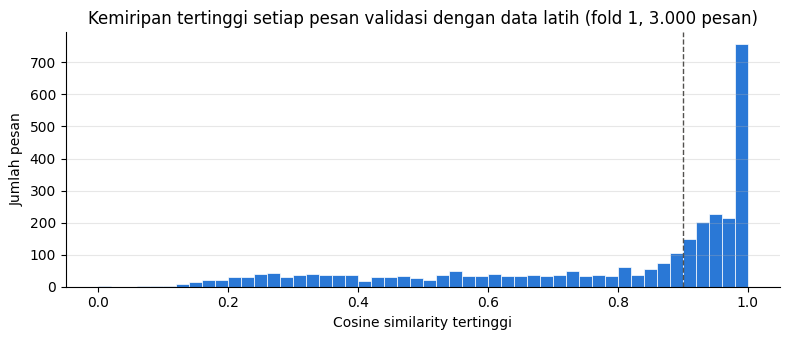

51.7% pesan validasi sampel memiliki pasangan near-duplicate di data latih. Pengaruhnya terhadap kesalahan model akhir diperiksa pada bagian G.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
T_tr, _, T_va = load_fold(0, 'tfidf_V2')
_, va0 = folds[0]
nd_sample = np.sort(rng.choice(len(va0), size=min(3000, len(va0)), replace=False))
max_similarity = np.zeros(len(nd_sample))
T_tr_t = T_tr.T.tocsr()
for start in range(0, len(nd_sample), 100):
    block = T_va[nd_sample[start:start + 100]] @ T_tr_t
    max_similarity[start:start + 100] = block.max(axis=1).toarray().ravel()
del T_tr, T_va, T_tr_t, block
gc.collect()

NEAR_DUP_THRESHOLD = 0.9
nd_index = va0[nd_sample]          # posisi pesan pada data training
nd_labels = y_train[nd_index]
near_dup = max_similarity >= NEAR_DUP_THRESHOLD
nd_table = pd.DataFrame({
    'jumlah pesan sampel': [int((nd_labels == c).sum()) for c in CLASS_IDS],
    'median kemiripan tertinggi': [np.median(max_similarity[nd_labels == c]) for c in CLASS_IDS],
    'near-duplicate ≥ 0,9 (%)': [near_dup[nd_labels == c].mean() * 100 for c in CLASS_IDS],
    'hampir identik ≥ 0,99 (%)': [(max_similarity[nd_labels == c] >= 0.99).mean() * 100 for c in CLASS_IDS],
}, index=CLASS_ORDER)
display(nd_table.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(max_similarity, bins=50, color='#2a78d6', edgecolor='white', linewidth=0.5)
ax.axvline(NEAR_DUP_THRESHOLD, color='#52514e', linestyle='--', linewidth=1)
ax.set_title('Kemiripan tertinggi setiap pesan validasi dengan data latih (fold 1, 3.000 pesan)')
ax.set_xlabel('Cosine similarity tertinggi')
ax.set_ylabel('Jumlah pesan')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

display(Markdown(
    f"{near_dup.mean() * 100:.1f}% pesan validasi sampel memiliki pasangan near-duplicate di data latih. "
    "Pengaruhnya terhadap kesalahan model akhir diperiksa pada bagian G."
))

# D. Diagnosis Bias–Variance dan Tuning Lanjutan

## D.1 Validation Curve: `alpha` Multinomial Naive Bayes

Pada Pertemuan 5, `alpha` terbaik (1,0) berada di ujung atas rentang yang diuji. Sel berikut menguji kembali `alpha` pada count unigram + bigram V2, termasuk nilai yang lebih besar.

| Parameter | Nilai yang diuji | Metode | Validasi |
| --- | --- | --- | --- |
| `alpha` | 0,25; 0,5; 1; 2; 4; 8 | *Grid search* | Stratified 5-fold CV |

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,MNB V2 (alpha=0.25),"count unigram + bigram V2, alpha=0.25",0.9088 ± 0.0011,0.9862 ± 0.0007,0.9109 ± 0.0058,0.7828 ± 0.0048,0.8489 ± 0.0050,0.5
1,MNB V2 (alpha=0.5),"count unigram + bigram V2, alpha=0.5",0.9111 ± 0.0010,0.9856 ± 0.0004,0.9134 ± 0.0057,0.7911 ± 0.0049,0.8551 ± 0.0050,0.7
2,MNB V2 (alpha=1.0),"count unigram + bigram V2, alpha=1.0",0.9127 ± 0.0013,0.9867 ± 0.0004,0.8902 ± 0.0069,0.8175 ± 0.0050,0.8669 ± 0.0050,0.4
3,MNB V2 (alpha=2.0),"count unigram + bigram V2, alpha=2.0",0.9071 ± 0.0017,0.9890 ± 0.0004,0.8192 ± 0.0106,0.8659 ± 0.0043,0.8708 ± 0.0046,0.3
4,MNB V2 (alpha=4.0),"count unigram + bigram V2, alpha=4.0",0.8822 ± 0.0029,0.9919 ± 0.0004,0.7023 ± 0.0113,0.9136 ± 0.0022,0.8589 ± 0.0042,0.3
5,MNB V2 (alpha=8.0),"count unigram + bigram V2, alpha=8.0",0.8325 ± 0.0042,0.9951 ± 0.0004,0.5603 ± 0.0108,0.9501 ± 0.0019,0.8343 ± 0.0042,0.3


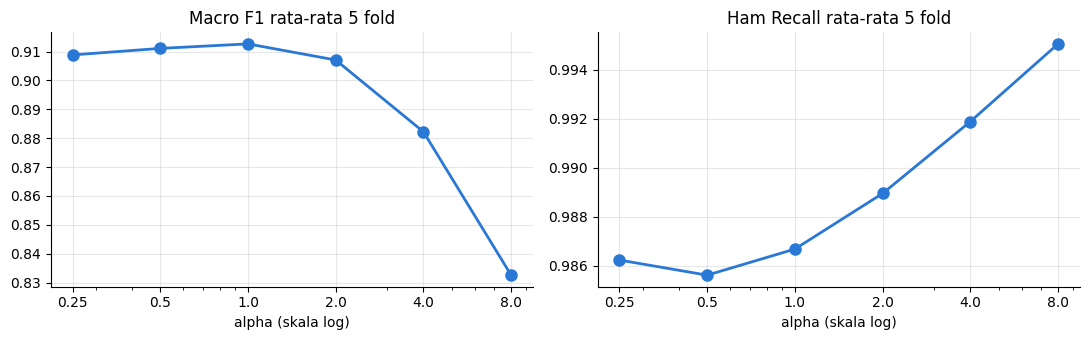

`alpha` terbaik pada teks V2 adalah **1.0**.

In [ ]:
ALPHA_GRID = [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]
alpha_names = []
for alpha in ALPHA_GRID:
    name = f'MNB V2 (alpha={alpha})'
    run_cv(name, 'count12_V2', mnb_fit_predict(alpha), f'count unigram + bigram V2, alpha={alpha}')
    alpha_names.append(name)
display(summary_table(alpha_names))

alpha_scores = pd.DataFrame({
    'alpha': ALPHA_GRID,
    'Macro F1': [mean_metric(n, 'Macro F1') for n in alpha_names],
    'Ham Recall': [mean_metric(n, 'Ham Recall') for n in alpha_names],
})
close = alpha_scores[alpha_scores['Macro F1'] >= alpha_scores['Macro F1'].max() - TIE_TOLERANCE]
BEST_ALPHA = float(close.sort_values('Ham Recall', ascending=False).iloc[0]['alpha'])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric in zip(axes, ['Macro F1', 'Ham Recall']):
    ax.plot(ALPHA_GRID, alpha_scores[metric], marker='o', markersize=8, linewidth=2, color='#2a78d6')
    ax.set_xscale('log')
    ax.set_xticks(ALPHA_GRID, [str(a) for a in ALPHA_GRID])
    ax.set_xlabel('alpha (skala log)')
    ax.set_title(f'{metric} rata-rata 5 fold')
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
edge = ' Nilai ini berada di ujung rentang yang diuji.' if BEST_ALPHA in (min(ALPHA_GRID), max(ALPHA_GRID)) else ''
display(Markdown(f"`alpha` terbaik pada teks V2 adalah **{BEST_ALPHA}**.{edge}"))

## D.2 Validation Curve: Jumlah Pohon LightGBM

Pada Pertemuan 5, jumlah pohon LightGBM ditetapkan dari uji pada sampel data. Sel berikut melatih LightGBM dengan 150 pohon pada fold 1, lalu menghitung Macro F1 setelah setiap 25 pohon. Skor dihitung pada data validasi fold 1 dan pada 20.000 pesan data latih fold 1. Selisih keduanya menunjukkan *overfitting*.

Jumlah pohon terkecil yang Macro F1 validasinya tidak lebih dari 0,001 di bawah nilai tertinggi dipilih, karena pohon yang lebih sedikit berarti training lebih cepat. Langkah ini membutuhkan sekitar 25 menit.

| Parameter | Nilai | Keterangan |
| --- | --- | --- |
| Fitur | Unigram count V2 yang muncul di minimal 20 pesan | Sama dengan Pertemuan 5 |
| `learning_rate`, `num_leaves`, `colsample_bytree` | 0,2; 63; 0,3 | Sama dengan Pertemuan 5 |
| Jumlah pohon | 25 sampai 150 | Diuji pada sel ini |

,jumlah pohon,Macro F1 data latih,Macro F1 validasi
0,25,0.9212,0.9184
1,50,0.9456,0.9381
2,75,0.9587,0.9445
3,100,0.9683,0.9493
4,125,0.9753,0.9523
5,150,0.9798,0.9545


Waktu: 38.7 menit


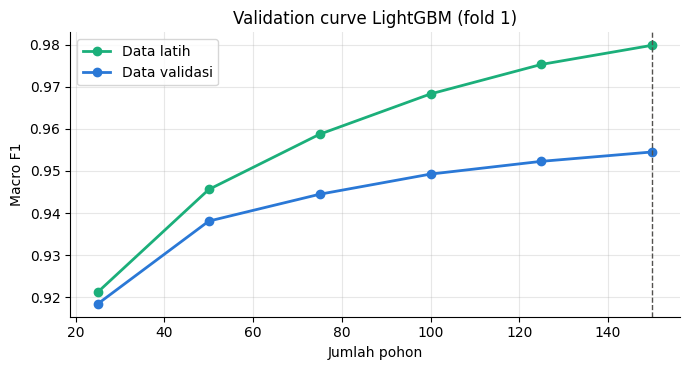

Jumlah pohon terpilih adalah **150**. Pada jumlah ini, Macro F1 data latih 0.9798 dan Macro F1 validasi 0.9545 (selisih 0.0253). Jumlah ini berada di ujung atas rentang yang diuji, sehingga pohon yang lebih banyak mungkin masih sedikit membantu.

In [ ]:
LGBM_BASE = dict(learning_rate=0.2, num_leaves=63, colsample_bytree=0.3,
                 random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
LGBM_MAX_TREES = 150
LGBM_MIN_DF = 20


def lgbm_columns(X_tr, k):
    unigram_mask = np.load(f'{CACHE_DIR}/unigram_mask_{k}.npy')
    document_frequency = np.asarray((X_tr > 0).sum(axis=0)).ravel()
    return np.flatnonzero(unigram_mask & (document_frequency >= LGBM_MIN_DF))


start = time.perf_counter()
X_tr0, y_tr0, X_va0 = load_fold(0, 'count12_V2')
lgbm_cols0 = lgbm_columns(X_tr0, 0)
lgbm_fold0 = lgb.LGBMClassifier(n_estimators=LGBM_MAX_TREES, **LGBM_BASE).fit(X_tr0[:, lgbm_cols0], y_tr0)
train_check = rng.choice(X_tr0.shape[0], size=min(20_000, X_tr0.shape[0]), replace=False)
tree_rows = []
for trees in range(25, LGBM_MAX_TREES + 1, 25):
    tree_rows.append({
        'jumlah pohon': trees,
        'Macro F1 data latih': f1_score(y_tr0[train_check], lgbm_fold0.predict(X_tr0[train_check][:, lgbm_cols0], num_iteration=trees), average='macro'),
        'Macro F1 validasi': f1_score(y_train[folds[0][1]], lgbm_fold0.predict(X_va0[:, lgbm_cols0], num_iteration=trees), average='macro'),
    })
tree_table = pd.DataFrame(tree_rows)
display(tree_table.round(4))
BEST_TREES = int(tree_table[tree_table['Macro F1 validasi'] >= tree_table['Macro F1 validasi'].max() - TIE_TOLERANCE]['jumlah pohon'].min())
print(f'Waktu: {(time.perf_counter() - start) / 60:.1f} menit')

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tree_table['jumlah pohon'], tree_table['Macro F1 data latih'], marker='o', linewidth=2, color='#1baf7a', label='Data latih')
ax.plot(tree_table['jumlah pohon'], tree_table['Macro F1 validasi'], marker='o', linewidth=2, color='#2a78d6', label='Data validasi')
ax.axvline(BEST_TREES, color='#52514e', linestyle='--', linewidth=1)
ax.set_xlabel('Jumlah pohon')
ax.set_ylabel('Macro F1')
ax.set_title('Validation curve LightGBM (fold 1)')
ax.legend()
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

gap = tree_table.set_index('jumlah pohon').loc[BEST_TREES]
tree_edge = (' Jumlah ini berada di ujung atas rentang yang diuji, sehingga pohon yang lebih banyak mungkin masih sedikit membantu.'
             if BEST_TREES == LGBM_MAX_TREES else '')
display(Markdown(
    f"Jumlah pohon terpilih adalah **{BEST_TREES}**. Pada jumlah ini, Macro F1 data latih {gap['Macro F1 data latih']:.4f} "
    f"dan Macro F1 validasi {gap['Macro F1 validasi']:.4f} (selisih {gap['Macro F1 data latih'] - gap['Macro F1 validasi']:.4f})."
    + tree_edge
))

## D.3 Learning Curve

*Learning curve* menunjukkan apakah model masih akan membaik jika diberi lebih banyak data. Sel berikut melatih Multinomial Naive Bayes dan Logistic Regression pada 10%, 25%, 50%, dan 100% data latih fold 1, lalu mengukur Macro F1 pada data latih yang dipakai dan pada data validasi fold 1.

Cara membaca:

- Jika Macro F1 validasi masih naik saat data ditambah, model belum jenuh dan lebih banyak data masih membantu.
- Jika Macro F1 data latih jauh di atas validasi, model cenderung *overfitting* (variance tinggi).
- Jika keduanya rendah dan berdekatan, model terlalu sederhana (bias tinggi).

Langkah ini membutuhkan sekitar 10 menit.

,model,proporsi data latih,jumlah pesan,Macro F1 data latih,Macro F1 validasi
0,Multinomial Naive Bayes,0.10,17852,0.9344,0.8127
1,Logistic Regression,0.10,17852,0.9987,0.9126
2,Multinomial Naive Bayes,0.25,44630,0.9519,0.8790
3,Logistic Regression,0.25,44630,0.9985,0.9272
4,Multinomial Naive Bayes,0.50,89260,0.9519,0.9053
5,Logistic Regression,0.50,89260,0.9963,0.9348
6,Multinomial Naive Bayes,1.00,178521,0.9383,0.9118
7,Logistic Regression,1.00,178521,0.9957,0.9426


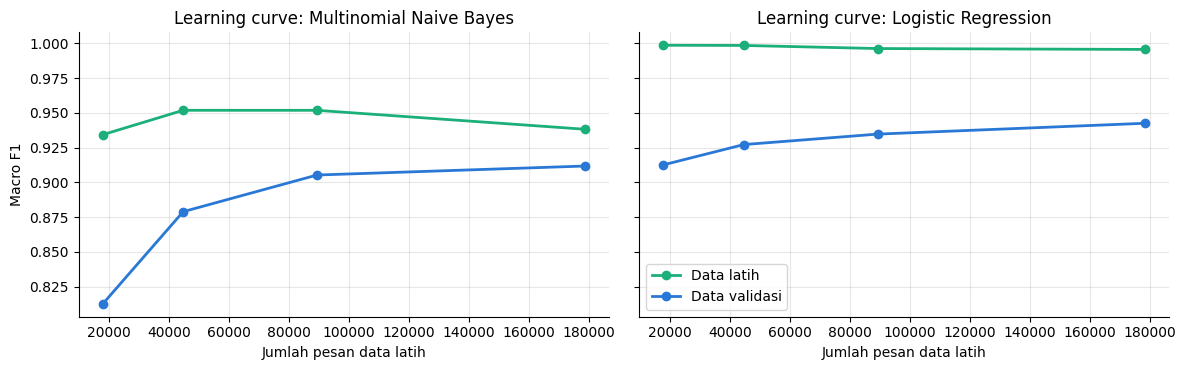

- **Multinomial Naive Bayes:** dari 50% ke 100% data, Macro F1 validasi naik 0.0065; selisih data latih dan validasi pada 100% data adalah 0.0265. Lebih banyak data masih membantu.
- **Logistic Regression:** dari 50% ke 100% data, Macro F1 validasi naik 0.0078; selisih data latih dan validasi pada 100% data adalah 0.0531. Lebih banyak data masih membantu. Selisih yang besar menunjukkan model cenderung *overfitting*.

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

FRACTIONS = [0.10, 0.25, 0.50, 1.00]
curve_rows = []
X_tr0_tfidf, _, X_va0_tfidf = load_fold(0, 'tfidf_V2')
order = rng.permutation(X_tr0.shape[0])
for fraction in FRACTIONS:
    rows = np.sort(order[: int(fraction * len(order))])
    check = rows if len(rows) <= 20_000 else np.sort(rng.choice(rows, size=20_000, replace=False))
    for model_name, X_fit, X_val, make_model in [
        ('Multinomial Naive Bayes', X_tr0, X_va0, lambda: MultinomialNB(alpha=BEST_ALPHA)),
        ('Logistic Regression', X_tr0_tfidf, X_va0_tfidf, lambda: LogisticRegression(C=64, max_iter=1000, random_state=RANDOM_STATE)),
    ]:
        model = make_model().fit(X_fit[rows], y_tr0[rows])
        curve_rows.append({
            'model': model_name, 'proporsi data latih': fraction, 'jumlah pesan': len(rows),
            'Macro F1 data latih': f1_score(y_tr0[check], model.predict(X_fit[check]), average='macro'),
            'Macro F1 validasi': f1_score(y_train[folds[0][1]], model.predict(X_val), average='macro'),
        })
curve_table = pd.DataFrame(curve_rows)
display(curve_table.round(4))
del X_tr0_tfidf, X_va0_tfidf
gc.collect()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
curve_notes, curve_slope = [], {}
for ax, model_name in zip(axes, ['Multinomial Naive Bayes', 'Logistic Regression']):
    part = curve_table[curve_table['model'] == model_name]
    ax.plot(part['jumlah pesan'], part['Macro F1 data latih'], marker='o', linewidth=2, color='#1baf7a', label='Data latih')
    ax.plot(part['jumlah pesan'], part['Macro F1 validasi'], marker='o', linewidth=2, color='#2a78d6', label='Data validasi')
    ax.set_title(f'Learning curve: {model_name}')
    ax.set_xlabel('Jumlah pesan data latih')
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    last, half = part.iloc[-1], part.iloc[-2]
    slope = last['Macro F1 validasi'] - half['Macro F1 validasi']
    train_gap = last['Macro F1 data latih'] - last['Macro F1 validasi']
    curve_slope[model_name] = slope
    curve_notes.append(
        f"- **{model_name}:** dari 50% ke 100% data, Macro F1 validasi {change_text(slope)}; "
        f"selisih data latih dan validasi pada 100% data adalah {train_gap:.4f}. "
        + ('Lebih banyak data masih membantu.' if slope > 0.002 else 'Tambahan data tidak lagi banyak membantu.')
        + (' Selisih yang besar menunjukkan model cenderung *overfitting*.' if train_gap > 0.03 else '')
    )
axes[0].set_ylabel('Macro F1')
axes[1].legend()
plt.tight_layout()
plt.show()
display(Markdown('\n'.join(curve_notes)))

# E. Seleksi Fitur

## E.1 Filter: Chi-Square

Count unigram + bigram V2 memiliki jutaan kolom. Seleksi fitur *filter* dengan chi-square memberi skor pada setiap kata berdasarkan seberapa kuat kemunculannya bergantung pada kelas, lalu hanya menyimpan k kata dengan skor tertinggi. Seleksi dilakukan di dalam setiap fold, hanya pada data latih fold tersebut, agar data validasi tidak memengaruhi pemilihan kata.

| Parameter | Nilai yang diuji | Model | Validasi |
| --- | --- | --- | --- |
| k (jumlah kata yang disimpan) | 10.000; 50.000; 200.000; 1.000.000; semua | Multinomial Naive Bayes, `alpha` terbaik D.1 | Stratified 5-fold CV |

k terkecil yang Macro F1-nya tidak lebih dari 0,001 di bawah model dengan semua kata dipilih, karena model dengan fitur lebih sedikit lebih sederhana dan lebih cepat. Langkah ini membutuhkan sekitar 15 menit.

In [ ]:
K_GRID = [k for k in [10_000, 50_000, 200_000, 1_000_000] if k < X_tr0.shape[1]]
best_alpha_name = f'MNB V2 (alpha={BEST_ALPHA})'
selection_names = []
for k_features in K_GRID:
    name = f'MNB V2 chi2 k={k_features:,}'
    run_cv(name, 'count12_V2', mnb_fit_predict(BEST_ALPHA, selector_k=k_features), f'alpha={BEST_ALPHA}, chi-square k={k_features:,}')
    selection_names.append(name)
display(summary_table(selection_names + [best_alpha_name]))

all_f1 = mean_metric(best_alpha_name, 'Macro F1')
eligible = [(k_features, name) for k_features, name in zip(K_GRID, selection_names)
            if mean_metric(name, 'Macro F1') >= all_f1 - TIE_TOLERANCE]
if eligible:
    BEST_K, FINAL_MNB = eligible[0]
else:
    BEST_K, FINAL_MNB = None, best_alpha_name
display(Markdown(
    f"Dengan semua kata, Macro F1 adalah {all_f1:.4f}. "
    + (f"Seleksi **{BEST_K:,} kata** memberi Macro F1 {mean_metric(FINAL_MNB, 'Macro F1'):.4f}, sehingga model akhir memakai {BEST_K:,} kata."
       if BEST_K else "Tidak ada nilai k yang mempertahankan Macro F1, sehingga model akhir memakai semua kata.")
))

from sklearn.feature_selection import chi2
X_tr0_count = X_tr0
chi_scores, _ = chi2(X_tr0_count, y_tr0)
terms0 = np.load(f'{CACHE_DIR}/terms_0.npy', allow_pickle=True)
feature_class = np.asarray([X_tr0_count[y_tr0 == c].sum(axis=0) for c in CLASS_IDS]).squeeze()
top = np.argsort(-chi_scores)[:20]
display(Markdown('#### 20 kata dengan skor chi-square tertinggi (fold 1)'))
display(pd.DataFrame({
    'kata': terms0[top],
    'skor chi-square': chi_scores[top].round(0),
    'kelas dengan kemunculan terbanyak': [CLASS_ORDER[int(feature_class[:, i].argmax())] for i in top],
}))

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,"MNB V2 chi2 k=10,000","alpha=1.0, chi-square k=10,000",0.8526 ± 0.0021,0.9629 ± 0.0013,0.8724 ± 0.0043,0.7533 ± 0.0050,0.8126 ± 0.0041,1.7
1,"MNB V2 chi2 k=50,000","alpha=1.0, chi-square k=50,000",0.8762 ± 0.0012,0.9736 ± 0.0005,0.9239 ± 0.0034,0.7613 ± 0.0048,0.8400 ± 0.0047,1.6
2,"MNB V2 chi2 k=200,000","alpha=1.0, chi-square k=200,000",0.8945 ± 0.0012,0.9793 ± 0.0008,0.9428 ± 0.0023,0.7678 ± 0.0045,0.8581 ± 0.0052,1.7
3,"MNB V2 chi2 k=1,000,000","alpha=1.0, chi-square k=1,000,000",0.9092 ± 0.0007,0.9834 ± 0.0005,0.9368 ± 0.0033,0.7865 ± 0.0046,0.8700 ± 0.0052,1.9
4,MNB V2 (alpha=1.0),"count unigram + bigram V2, alpha=1.0",0.9127 ± 0.0013,0.9867 ± 0.0004,0.8902 ± 0.0069,0.8175 ± 0.0050,0.8669 ± 0.0050,0.4


Dengan semua kata, Macro F1 adalah 0.9127. Tidak ada nilai k yang mempertahankan Macro F1, sehingga model akhir memakai semua kata.

#### 20 kata dengan skor chi-square tertinggi (fold 1)

,kata,skor chi-square,kelas dengan kemunculan terbanyak
0,the,365864.0,Ham
1,to,229777.0,Ham
2,numtoken,224855.0,Ham
3,enron,157698.0,Ham
4,numtoken numtoken,148055.0,Ham
5,of,118850.0,Ham
6,and,116900.0,Ham
7,in,103197.0,Ham
8,datetoken,87244.0,Ham
9,on,80928.0,Ham


## E.2 Model-Based: Pentingnya Fitur pada LightGBM

LightGBM mencatat seberapa besar setiap kata menurunkan kesalahan saat dipakai untuk membagi data pada pohon (*gain*). Tabel berikut menampilkan 20 kata dengan *gain* tertinggi pada model fold 1 dari D.2. *Gain* menunjukkan kata yang paling banyak dipakai model, tetapi tidak menunjukkan arah pengaruhnya. Interpretasi arah pengaruh dilakukan pada evaluasi akhir.

In [ ]:
gain = lgbm_fold0.booster_.feature_importance(importance_type='gain')
top_gain = np.argsort(-gain)[:20]
display(pd.DataFrame({
    'kata': terms0[lgbm_cols0[top_gain]],
    'gain (% dari total)': (gain[top_gain] / gain.sum() * 100).round(2),
}))

,kata,gain (% dari total)
0,to,4.62
1,enron,4.33
2,original,2.82
3,the,2.69
4,thanks,2.32
5,http,2.14
6,org,1.96
7,wrote,1.65
8,datetoken,1.64
9,and,1.63


# F. Model Akhir pada Teks V2

## F.1 Model Dasar

Sel berikut membentuk prediksi *out-of-fold* ketiga model dasar pada teks V2:

| Model | Konfigurasi |
| --- | --- |
| Multinomial Naive Bayes | Count unigram + bigram V2, `alpha` dari D.1, jumlah kata dari E.1 |
| Logistic Regression | TF-IDF unigram V2, `C=64` (hasil B.3) |
| LightGBM | Unigram count V2 (`min_df=20`), jumlah pohon dari D.2. Model fold 1 dari D.2 dipakai ulang. |

Langkah ini membutuhkan sekitar 70 menit untuk LightGBM.

In [ ]:
LR_NAME = 'LR V2'
LGBM_NAME = 'LightGBM V2'


def lgbm_fit_predict(X_tr, y_tr, X_va, k):
    if k == 0:
        return np.log(np.clip(lgbm_fold0.predict_proba(X_va[:, lgbm_cols0], num_iteration=BEST_TREES), 1e-15, 1.0))
    columns = lgbm_columns(X_tr, k)
    model = lgb.LGBMClassifier(n_estimators=BEST_TREES, **LGBM_BASE).fit(X_tr[:, columns], y_tr)
    return np.log(np.clip(model.predict_proba(X_va[:, columns]), 1e-15, 1.0))


del X_tr0, X_va0
gc.collect()
run_cv(LGBM_NAME, 'count12_V2', lgbm_fit_predict, f'unigram count V2 min_df={LGBM_MIN_DF}, {BEST_TREES} pohon')
display(summary_table([FINAL_MNB, LR_NAME, LGBM_NAME]))

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,MNB V2 (alpha=1.0),"count unigram + bigram V2, alpha=1.0",0.9127 ± 0.0013,0.9867 ± 0.0004,0.8902 ± 0.0069,0.8175 ± 0.0050,0.8669 ± 0.0050,0.4
1,LR V2,"TF-IDF unigram V2, C=64",0.9423 ± 0.0014,0.9856 ± 0.0005,0.8819 ± 0.0060,0.9036 ± 0.0023,0.9658 ± 0.0016,13.4
2,LightGBM V2,"unigram count V2 min_df=20, 150 pohon",0.9538 ± 0.0005,0.9790 ± 0.0003,0.9191 ± 0.0038,0.9242 ± 0.0042,0.9792 ± 0.0011,156.3


## F.2 Stacking dan Uji Tanpa Multinomial Naive Bayes

Stacking dibentuk dengan cara yang sama seperti Pertemuan 5: *meta-model* Logistic Regression dilatih pada log-probabilitas *out-of-fold* model dasar (dibatasi pada rentang −30 sampai 0) dan dievaluasi dengan lima fold yang sama.

Empat kombinasi diuji. Kombinasi tanpa Multinomial Naive Bayes menunjukkan apakah model tersebut benar-benar menambah informasi pada stacking.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def run_stacking(name, base_names):
    features = np.hstack([np.clip(cv_results[n]['log_proba'], -30, 0) for n in base_names])
    log_proba = np.zeros((len(y_train), 3))
    start = time.perf_counter()
    for tr, va in folds:
        meta = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        meta.fit(features[tr], y_train[tr])
        log_proba[va] = meta.predict_log_proba(features[va])
    store_result(name, log_proba, ' + '.join(base_names), (time.perf_counter() - start) / 60)


STACKS = {
    'Stacking MNB + LR + LightGBM': [FINAL_MNB, LR_NAME, LGBM_NAME],
    'Stacking LR + LightGBM': [LR_NAME, LGBM_NAME],
    'Stacking MNB + LightGBM': [FINAL_MNB, LGBM_NAME],
    'Stacking MNB + LR': [FINAL_MNB, LR_NAME],
}
for name, bases in STACKS.items():
    run_stacking(name, bases)
FINALISTS = [FINAL_MNB, LR_NAME, LGBM_NAME] + list(STACKS)
display(summary_table(FINALISTS))

,model,konfigurasi,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,waktu (menit)
0,MNB V2 (alpha=1.0),"count unigram + bigram V2, alpha=1.0",0.9127 ± 0.0013,0.9867 ± 0.0004,0.8902 ± 0.0069,0.8175 ± 0.0050,0.8669 ± 0.0050,0.4
1,LR V2,"TF-IDF unigram V2, C=64",0.9423 ± 0.0014,0.9856 ± 0.0005,0.8819 ± 0.0060,0.9036 ± 0.0023,0.9658 ± 0.0016,13.4
2,LightGBM V2,"unigram count V2 min_df=20, 150 pohon",0.9538 ± 0.0005,0.9790 ± 0.0003,0.9191 ± 0.0038,0.9242 ± 0.0042,0.9792 ± 0.0011,156.3
3,Stacking MNB + LR + LightGBM,MNB V2 (alpha=1.0) + LR V2 + LightGBM V2,0.9589 ± 0.0007,0.9876 ± 0.0007,0.9231 ± 0.0044,0.9303 ± 0.0033,0.9814 ± 0.0011,0.4
4,Stacking LR + LightGBM,LR V2 + LightGBM V2,0.9588 ± 0.0010,0.9872 ± 0.0008,0.9224 ± 0.0047,0.9300 ± 0.0033,0.9809 ± 0.0011,0.3
5,Stacking MNB + LightGBM,MNB V2 (alpha=1.0) + LightGBM V2,0.9557 ± 0.0006,0.9832 ± 0.0006,0.9224 ± 0.0041,0.9265 ± 0.0037,0.9803 ± 0.0011,0.3
6,Stacking MNB + LR,MNB V2 (alpha=1.0) + LR V2,0.9436 ± 0.0005,0.9870 ± 0.0007,0.8892 ± 0.0044,0.9014 ± 0.0039,0.9686 ± 0.0015,0.2


## F.3 Pemilihan pada Target Ham Recall 99,5%

Setiap finalis disetel dengan pergeseran threshold Ham agar Ham Recall minimal 99,5% (cara yang sama dengan Pertemuan 5). Model dengan Macro F1 tertinggi dipilih. Jika selisih Macro F1 kurang dari 0,001, dipilih model dengan jumlah model dasar lebih sedikit, karena lebih sederhana.

In [ ]:
def ham_margin(log_proba):
    return log_proba[:, 0] - np.max(log_proba[:, 1:], axis=1)


def ham_bias_for_target(name, target=HAM_RECALL_TARGET):
    margin = ham_margin(cv_results[name]['log_proba'])[y_train == 0]
    return max(0.0, -np.quantile(margin, 1 - target, method='lower'))


HAM_BIAS = {name: ham_bias_for_target(name) for name in FINALISTS}
n_bases = {name: len(STACKS.get(name, [name])) for name in FINALISTS}
target_rows = []
for name in FINALISTS:
    scores = per_fold_metrics(name, HAM_BIAS[name])
    target_rows.append({
        'model': name,
        'jumlah model dasar': n_bases[name],
        'b': round(HAM_BIAS[name], 3),
        'Ham Recall': scores['Ham Recall'].mean(),
        'Macro F1': scores['Macro F1'].mean(),
        'Macro F1 simpangan baku': scores['Macro F1'].std(ddof=0),
        'Phish Recall': scores['Phish Recall'].mean(),
        'Phish Precision': scores['Phish Precision'].mean(),
        **error_counts(y_train, predict_with_ham_bias(cv_results[name]['log_proba'], HAM_BIAS[name])),
    })
target_table = pd.DataFrame(target_rows)
display(target_table.round(4))

close = target_table[target_table['Macro F1'] >= target_table['Macro F1'].max() - TIE_TOLERANCE]
FINAL_MODEL = close.sort_values(['jumlah model dasar', 'Macro F1'], ascending=[True, False]).iloc[0]['model']
FINAL_BIAS = HAM_BIAS[FINAL_MODEL]
final_row = target_table.set_index('model').loc[FINAL_MODEL]
with_mnb = target_table.set_index('model').loc['Stacking MNB + LR + LightGBM']
without_mnb = target_table.set_index('model').loc['Stacking LR + LightGBM']
mnb_gain = with_mnb['Macro F1'] - without_mnb['Macro F1']

final_text = f'''
### Model terpilih

**{FINAL_MODEL}** (b = {FINAL_BIAS:.3f}): Macro F1 {final_row['Macro F1']:.4f} pada Ham Recall {final_row['Ham Recall']:.4f}. Model ini kehilangan {int(final_row['Ham → Spam'] + final_row['Ham → Phish']):,} email sah dari {int((y_train == 0).sum()):,}, serta meloloskan {int(final_row['Phish → Ham']):,} phishing dan {int(final_row['Spam → Ham']):,} spam ke kotak masuk.

**Peran Multinomial Naive Bayes.** Pada Ham Recall yang sama, menambahkan Multinomial Naive Bayes ke stacking LR + LightGBM membuat Macro F1 {change_text(mnb_gain)} dan mengubah phishing yang lolos ke kotak masuk dari {int(without_mnb['Phish → Ham']):,} menjadi {int(with_mnb['Phish → Ham']):,} pesan. {'Multinomial Naive Bayes menambah informasi pada stacking.' if mnb_gain >= TIE_TOLERANCE else 'Multinomial Naive Bayes tidak menambah informasi yang berarti pada stacking.'}
'''
display(Markdown(final_text))

,model,jumlah model dasar,b,Ham Recall,Macro F1,Macro F1 simpangan baku,Phish Recall,Phish Precision,Ham → Spam,Ham → Phish,Phish → Ham,Phish → Spam,Spam → Phish,Spam → Ham
0,MNB V2 (alpha=1.0),1,31.865,0.995,0.8658,0.0014,0.8028,0.8566,395,115,3999,2758,4490,14981
1,LR V2,1,2.835,0.995,0.9325,0.0009,0.8693,0.9139,433,78,829,3651,2729,4426
2,LightGBM V2,1,1.648,0.995,0.9386,0.0022,0.8954,0.9389,445,65,1294,2291,1932,6050
3,Stacking MNB + LR + LightGBM,3,1.625,0.995,0.9551,0.0010,0.9154,0.9332,458,53,516,2384,2192,2309
4,Stacking LR + LightGBM,2,1.781,0.995,0.9533,0.0011,0.9126,0.9349,451,59,597,2398,2118,2756
5,Stacking MNB + LightGBM,2,1.842,0.995,0.9478,0.0014,0.9079,0.9318,462,48,907,2250,2230,3779
6,Stacking MNB + LR,2,1.916,0.995,0.9384,0.0007,0.8824,0.9056,453,58,634,3395,3097,3048



### Model terpilih

**Stacking MNB + LR + LightGBM** (b = 1.625): Macro F1 0.9551 pada Ham Recall 0.9950. Model ini kehilangan 511 email sah dari 102,192, serta meloloskan 516 phishing dan 2,309 spam ke kotak masuk.

**Peran Multinomial Naive Bayes.** Pada Ham Recall yang sama, menambahkan Multinomial Naive Bayes ke stacking LR + LightGBM membuat Macro F1 naik 0.0018 dan mengubah phishing yang lolos ke kotak masuk dari 597 menjadi 516 pesan. Multinomial Naive Bayes menambah informasi pada stacking.


## F.4 Menyimpan Hasil

Sel berikut menyimpan hasil yang dibutuhkan evaluasi akhir dan dokumentasi:

| Berkas | Isi |
| --- | --- |
| `oof_log_proba.npz` | Log-probabilitas *out-of-fold* setiap model, label training, dan indeks fold |
| `final_config.json` | Versi teks, hyperparameter setiap model dasar, model terpilih, dan nilai b |
| `experiment_log.csv` | Satu baris per konfigurasi: model, konfigurasi, metrik rata-rata ± simpangan baku, dan waktu |
| `requirements.txt` | Versi library yang dipakai notebook ini |

In [ ]:
fold_of_row = np.empty(len(y_train), dtype=int)
for k, (_, va) in enumerate(folds):
    fold_of_row[va] = k
np.savez_compressed(
    f'{ARTIFACT_DIR}/oof_log_proba.npz',
    y_train=y_train,
    fold_of_row=fold_of_row,
    **{name.replace(' ', '_'): result['log_proba'] for name, result in cv_results.items()},
)
final_config = {
    'text_variant': 'V2',
    'punctuation_pattern': PUNCTUATION_PATTERN,
    'timestamp_pattern': TIMESTAMP_PATTERN,
    'number_pattern': NUMBER_PATTERN,
    'date_pattern': DATE_PATTERN,
    'mnb': {'representation': 'count unigram+bigram, min_df=2', 'alpha': BEST_ALPHA, 'chi2_k': BEST_K},
    'lr': {'representation': 'tfidf unigram, sublinear_tf', 'C': 64},
    'lightgbm': {'representation': f'unigram count, min_df={LGBM_MIN_DF}', 'n_estimators': BEST_TREES,
                 **{key: value for key, value in LGBM_BASE.items() if key not in ('verbose', 'n_jobs')}},
    'stacking_meta': 'StandardScaler + LogisticRegression on log-probabilities clipped to [-30, 0]',
    'final_model': FINAL_MODEL,
    'final_model_bases': STACKS.get(FINAL_MODEL, [FINAL_MODEL]),
    'ham_bias_b': float(FINAL_BIAS),
    'ham_recall_target': HAM_RECALL_TARGET,
    'random_state': RANDOM_STATE,
}
with open(f'{ARTIFACT_DIR}/final_config.json', 'w') as handle:
    json.dump(final_config, handle, indent=2, default=str)

log_table = summary_table(list(cv_results))
log_table.insert(0, 'tanggal', time.strftime('%Y-%m-%d'))
log_table.to_csv(f'{ARTIFACT_DIR}/experiment_log.csv', index=False)

with open(f'{ARTIFACT_DIR}/requirements.txt', 'w') as handle:
    handle.write(f'python=={sys.version.split()[0]}\n')
    import scipy
    import matplotlib
    for package, module in [('scikit-learn', sklearn), ('lightgbm', lgb), ('numpy', np), ('pandas', pd),
                            ('scipy', scipy), ('matplotlib', matplotlib)]:
        handle.write(f'{package}=={module.__version__}\n')

print('Tersimpan di', ARTIFACT_DIR, ':', sorted(os.listdir(ARTIFACT_DIR)))

Tersimpan di m07_artifacts : ['experiment_log.csv', 'final_config.json', 'oof_log_proba.npz', 'requirements.txt']


# G. Analisis Kesalahan

Bagian ini membaca kesalahan model terpilih pada target Ham Recall 99,5%, bukan hanya jumlahnya. Kesalahan dikelompokkan menurut tiga ciri pesan:

1. **Panjang pesan** (jumlah kata pada teks asli).
2. **Karakter non-ASCII**, sebagai petunjuk teks yang bukan bahasa Inggris atau rusak.
3. **Status near-duplicate** dari bagian C (hanya untuk 3.000 pesan sampel fold 1).

Untuk setiap kelompok, tabel menampilkan tiga kesalahan prioritas: persentase email sah yang hilang, persentase phishing yang masuk kotak masuk, dan persentase spam yang masuk kotak masuk.

In [ ]:
final_pred = predict_with_ham_bias(cv_results[FINAL_MODEL]['log_proba'], FINAL_BIAS)
word_count = X_train.str.count(r'\S+').to_numpy()
non_ascii = X_train.str.contains(r'[^\x00-\x7F]', regex=True).to_numpy()


def error_profile(groups, labels):
    rows = []
    for label in labels:
        mask = groups == label
        ham, phish, spam = mask & (y_train == 0), mask & (y_train == 1), mask & (y_train == 2)
        rows.append({
            'kelompok': label,
            'jumlah pesan': int(mask.sum()),
            'email sah hilang (%)': (final_pred[ham] != 0).mean() * 100 if ham.any() else np.nan,
            'phishing masuk kotak masuk (%)': (final_pred[phish] == 0).mean() * 100 if phish.any() else np.nan,
            'spam masuk kotak masuk (%)': (final_pred[spam] == 0).mean() * 100 if spam.any() else np.nan,
        })
    return pd.DataFrame(rows)


length_group = np.select([word_count <= 10, word_count <= 50, word_count <= 200], ['≤ 10 kata', '11–50 kata', '51–200 kata'], '> 200 kata')
length_profile = error_profile(length_group, ['≤ 10 kata', '11–50 kata', '51–200 kata', '> 200 kata'])
display(Markdown('#### Menurut panjang pesan'))
display(length_profile.round(2))

ascii_group = np.where(non_ascii, 'memuat non-ASCII', 'ASCII saja')
ascii_profile = error_profile(ascii_group, ['ASCII saja', 'memuat non-ASCII'])
display(Markdown('#### Menurut karakter non-ASCII'))
display(ascii_profile.round(2))

nd_correct = final_pred[nd_index] == y_train[nd_index]
nd_profile = pd.DataFrame({
    'kelompok': ['near-duplicate (≥ 0,9)', 'bukan near-duplicate'],
    'jumlah pesan': [int(near_dup.sum()), int((~near_dup).sum())],
    'prediksi salah (%)': [(~nd_correct[near_dup]).mean() * 100 if near_dup.any() else np.nan,
                           (~nd_correct[~near_dup]).mean() * 100],
})
display(Markdown('#### Menurut status near-duplicate (sampel fold 1)'))
display(nd_profile.round(2))

#### Menurut panjang pesan

,kelompok,jumlah pesan,email sah hilang (%),phishing masuk kotak masuk (%),spam masuk kotak masuk (%)
0,≤ 10 kata,5851,6.09,8.14,9.22
1,11–50 kata,51509,0.51,2.40,3.32
2,51–200 kata,93312,0.32,0.77,2.07
3,> 200 kata,72480,0.40,0.37,2.20


#### Menurut karakter non-ASCII

,kelompok,jumlah pesan,email sah hilang (%),phishing masuk kotak masuk (%),spam masuk kotak masuk (%)
0,ASCII saja,204571,0.47,1.49,2.93
1,memuat non-ASCII,18581,1.00,2.71,1.10


#### Menurut status near-duplicate (sampel fold 1)

,kelompok,jumlah pesan,prediksi salah (%)
0,"near-duplicate (≥ 0,9)",1550,3.81
1,bukan near-duplicate,1450,4.28


Sel berikut menampilkan contoh pesan untuk dua kesalahan prioritas tertinggi. Teks ditampilkan dalam versi asli (V0) agar mudah dibaca.

In [ ]:
def show_examples(actual, predicted_classes, title, n=10):
    mask = (y_train == actual) & np.isin(final_pred, predicted_classes)
    index = np.flatnonzero(mask)
    display(Markdown(f'#### {title} ({len(index):,} pesan)'))
    if len(index) == 0:
        return
    sample = np.sort(rng.choice(index, size=min(n, len(index)), replace=False))
    display(pd.DataFrame({
        'prediksi': [LABEL_NAMES[c] for c in final_pred[sample]],
        'jumlah kata': word_count[sample],
        'non-ASCII': non_ascii[sample],
        'cuplikan teks': X_train.iloc[sample].str.slice(0, 160).to_numpy(),
    }))


show_examples(0, [1, 2], 'Email sah yang hilang (Ham → Spam atau Phish)')
show_examples(1, [0], 'Phishing yang masuk kotak masuk (Phish → Ham)')

short = length_profile.set_index('kelompok')
worst_ham_group = short['email sah hilang (%)'].idxmax()
worst_phish_group = short['phishing masuk kotak masuk (%)'].idxmax()
ascii_view = ascii_profile.set_index('kelompok')
nd_view = nd_profile.set_index('kelompok')
error_text = f'''
### Pola kesalahan

- Email sah paling sering hilang pada kelompok **{worst_ham_group}** ({short.loc[worst_ham_group, 'email sah hilang (%)']:.2f}%, dibandingkan {100 - final_row['Ham Recall'] * 100:.2f}% secara keseluruhan).
- Phishing paling sering lolos ke kotak masuk pada kelompok **{worst_phish_group}** ({short.loc[worst_phish_group, 'phishing masuk kotak masuk (%)']:.2f}%).
- Email sah yang memuat karakter non-ASCII hilang sebanyak {ascii_view.loc['memuat non-ASCII', 'email sah hilang (%)']:.2f}%, dibandingkan {ascii_view.loc['ASCII saja', 'email sah hilang (%)']:.2f}% pada teks ASCII saja.
- Pada sampel fold 1, kesalahan prediksi pesan near-duplicate adalah {nd_view.iloc[0]['prediksi salah (%)']:.2f}%, dibandingkan {nd_view.iloc[1]['prediksi salah (%)']:.2f}% pada pesan lainnya.
'''
display(Markdown(error_text))

#### Email sah yang hilang (Ham → Spam atau Phish) (511 pesan)

,prediksi,jumlah kata,non-ASCII,cuplikan teks
0,Spam,931,False,you are receiving this custom newsletter because you signed up to receive t he travel deals alert newsletter from cheapflights com may escapenumber escapenumber
1,Spam,10,False,an important visual describing our current energy crisis windmilldavis gif
2,Spam,185,False,dear richard welcome and thank you for registering with hotwire you are registered under the following email address richard shapiro enron com please note that
3,Spam,286,False,upon thinking about your comment i find that personally the ghost material might be a bit heavily used in her novel but i personally believe it adds a bit of ad
4,Phish,3,False,watch whole thing
5,Spam,1171,False,praise for bush from andrew sullivan prominent liberal interesting andrew sullivan in the london times no eloquence can match the impact of their evil americans
6,Spam,1618,False,this is a multi part message in mime format escapelong content type text plain charset iso escapenumber escapenumber content transfer encoding escapenumberbit j
7,Phish,30,False,let know need help w cooking antibiotics week longer infectious even still sound like shat c catherine kocarek jewett department internal medicine harborview me
8,Spam,22899,True,riffx wavefmt datas  y  z yw   zuvx ytmjhedflnmknw   pjikpoquwusomquy  xqmhiox  x
9,Spam,410,False,image image image image image image image image image image image image image image image image image sears com image gifts for your family from sears image sea


#### Phishing yang masuk kotak masuk (Phish → Ham) (516 pesan)

,prediksi,jumlah kata,non-ASCII,cuplikan teks
0,Ham,18,False,carolynn everett redresssk5paloaltocommonscom world may one person one person may world httpuaqdmotivationballcom thu 07 aug 2008 135316 0300
1,Ham,17,False,help center info660508367168708400334271260866065842565402757531620311248823730000285682383counsellingonlineorgau 5222022 114033 pm sun 22 may 2022 234034 0000
2,Ham,227,False,wood tom tomwoodkarchernacom dear colleague department performing system maintenance reconfiguration core switches performing major infrastructure upgrade serve
3,Ham,12,False,nadine greenberg affablyuf10carrollextcom fastshippinginternetpricesfdaapproved httpnhk9ogbaylivefilestorecomy1phqwcigd0nqvzoaujij1d_1dxwrmo7jvedalxtb8g5m7hkb4i
4,Ham,12,False,dwayne zimmerman capitalizekyn1painstandardscom pharmacyphentrimineuslicensed httpwmz84gbaylivefilestorecomy1p_guerurfqhsxx8z3i9gdda6rnynvryza9iuy7zqxx_v_wqv253
5,Ham,16,False,guide thru answers questions laser vision correction good chance could throw glasses contacts away information tuaujryt
6,Ham,10,False,13 1891 collect call alyssa milano 1824 small world songs
7,Ham,143,False,amazing sxsxth hope use hostettler kucan liquefaranno nl ha maritavate got vi co din named parac odin x nax popular products http w net mypillsplace com x 8 tl
8,Ham,67,False,utf8qapple20support ticket1541545idapplesupportcompany review case reference a1900xd180 id 1900x10d solutionid 12a9fjak94jf9ak recent summary existing case case
9,Ham,12,False,maxine ramos seismologistslyg22wahcoitorg healthylifecertifiedhealth httpkk1vbwblulivefilestorecomy1p9yeouluxvtx6hddhacryfft5u4merx7oqdwnid6p1ugh0dwhpwijtyy5xzx



### Pola kesalahan

- Email sah paling sering hilang pada kelompok **≤ 10 kata** (6.09%, dibandingkan 0.50% secara keseluruhan).
- Phishing paling sering lolos ke kotak masuk pada kelompok **≤ 10 kata** (8.14%).
- Email sah yang memuat karakter non-ASCII hilang sebanyak 1.00%, dibandingkan 0.47% pada teks ASCII saja.
- Pada sampel fold 1, kesalahan prediksi pesan near-duplicate adalah 3.81%, dibandingkan 4.28% pada pesan lainnya.


# H. Temuan dan Keputusan

Sel berikut merangkum temuan notebook ini.

In [ ]:
summary = f'''
1. **Hipotesis 4.** Menyeragamkan angka dan tanggal membuat Macro F1 Multinomial Naive Bayes {change_text(drops['Multinomial Naive Bayes'])} dan Logistic Regression {change_text(drops['Logistic Regression'])}. Hipotesis 4 **{'didukung' if H4_SUPPORTED else 'tidak didukung'}**. Model akhir memakai teks V2.
2. **Near-duplicate.** {near_dup.mean() * 100:.1f}% pesan validasi sampel memiliki pasangan dengan kemiripan minimal 0,9 di data latih.
3. **Tuning dan bias–variance.** `alpha` terbaik {BEST_ALPHA}; jumlah pohon LightGBM {BEST_TREES}. Dari 50% ke 100% data latih, Macro F1 validasi Multinomial Naive Bayes {change_text(curve_slope['Multinomial Naive Bayes'])} dan Logistic Regression {change_text(curve_slope['Logistic Regression'])}.
4. **Seleksi fitur.** {'Chi-square dengan ' + f'{BEST_K:,}' + ' kata mempertahankan Macro F1 Multinomial Naive Bayes.' if BEST_K else 'Chi-square tidak mempertahankan Macro F1, sehingga semua kata dipakai.'}
5. **Model akhir.** {FINAL_MODEL} dengan b = {FINAL_BIAS:.3f}: Macro F1 {final_row['Macro F1']:.4f} pada Ham Recall {final_row['Ham Recall']:.4f}.
6. **Kesalahan.** Email sah paling sering hilang pada pesan {worst_ham_group}, dan phishing paling sering lolos pada pesan {worst_phish_group}.
'''
display(Markdown(summary))


1. **Hipotesis 4.** Menyeragamkan angka dan tanggal membuat Macro F1 Multinomial Naive Bayes turun 0.0444 dan Logistic Regression turun 0.0263. Hipotesis 4 **didukung**. Model akhir memakai teks V2.
2. **Near-duplicate.** 51.7% pesan validasi sampel memiliki pasangan dengan kemiripan minimal 0,9 di data latih.
3. **Tuning dan bias–variance.** `alpha` terbaik 1.0; jumlah pohon LightGBM 150. Dari 50% ke 100% data latih, Macro F1 validasi Multinomial Naive Bayes naik 0.0065 dan Logistic Regression naik 0.0078.
4. **Seleksi fitur.** Chi-square tidak mempertahankan Macro F1, sehingga semua kata dipakai.
5. **Model akhir.** Stacking MNB + LR + LightGBM dengan b = 1.625: Macro F1 0.9551 pada Ham Recall 0.9950.
6. **Kesalahan.** Email sah paling sering hilang pada pesan ≤ 10 kata, dan phishing paling sering lolos pada pesan ≤ 10 kata.


**Rencana berikutnya: evaluasi akhir.**

1. Ketiga model dasar dilatih ulang pada seluruh data training V2 dengan konfigurasi `final_config.json`.
2. *Meta-model* dilatih pada prediksi *out-of-fold* yang tersimpan, lalu nilai b diterapkan.
3. Model akhir diuji **satu kali** pada data testing. Hasilnya dibandingkan dengan baseline Pertemuan 3 pada data testing yang sama.
4. Interpretasi model akhir dan *model card* disusun dari hasil tersebut.